# Toy MC for LXe SiPM Degradation Beamtime

This notebook simulates the sort of data we would get out of the Fall 2026 beamtime by making a random MC of n_samples datapoints of SiPM data (ie. $N_{pe}$) as a function of exposure to see how well we can recover the degradation time constants given our setup. User tunable parameters in this notebook:
- `nominal_npe` --> the number of photoelectrons the SiPMs were collecting before irradiation
- `exposure` --> the calculated amount of exposure the SiPMs received 
- `n_samples` --> how many datapoints we're working with
- `gain_spread` & `fec_spread` --> these are percentage values we get from calibration runs. That is, how much spread is there in our gain/excess charge calibrations? (if there is a 5% variation in gain calculations, input `gain_spread = 5`)
- `amp_fast`, `amp_slow`, `tau_fast`, `tau_slow` --> __truth info__: the amplitudes and time constants of the double exponential this model convolves with. Amps are how much % drop in $N_{pe}$ we see and taus are how much exposure we see that drop over (so `amp_fast = 7` and `tau_fast = 5e9` means 7% drop in $N_{pe}$ over 5e9 photons/$\text{mm}^2$ exposure)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from matplotlib.lines import Line2D
from scipy.optimize import nnls, least_squares

In [2]:
## user set data
exposure = np.arange(0, 2.5e10, 10000)
nominal_npe = 35000

amp_fast, tau_fast = 60, 2e9 # 60% drop in 2e9 exposure (fast)
amp_slow, tau_slow = 30, 4e10 #30% drop in 4e10 exposure (slow)

n_samples = 300 #how many samples will we have for toy data

gain_spread = 1.5
fec_spread = 1.0

## Create toy data

In [3]:
def decay_npe(exposure, nominal, amp_fast, tau_fast, amp_slow, tau_slow):
    """ 
    apply double exponential decay to an otherwise flat-baseline npe as a function of exposure
    """
    amp_fast_pct, amp_slow_pct = amp_fast/100, amp_slow/100
    baseline= 1-amp_fast_pct-amp_slow_pct
    lineshape = baseline+(amp_fast_pct*np.exp(-exposure/tau_fast))+(amp_slow_pct*np.exp(-exposure/tau_slow))
    return nominal*lineshape

def smear_npe(npe_clean, gain_spread, fec_spread, rng):
    """"
    add randomly-sampled gain and fec spread from gaussian distributions
    """
    n_samples = len(npe_clean)
    gain_noise = rng.normal(1.0, gain_spread/100, size=n_samples)
    fec_noise = rng.normal(1.0, fec_spread/100, size=n_samples)
    return npe_clean/(gain_noise*fec_noise)

def sample_toy_data(exposure, npe_clean, n_samples, gain_spread, fec_spread, seed=None):
    """
    sample from n_points data (mimicks real data) and apply noise
    """
    rng = np.random.default_rng(seed)
    idx = np.sort(rng.choice(len(exposure), size=n_samples, replace=False))
    sampled_exp = exposure[idx]
    sampled_npe_clean = npe_clean[idx]
    sampled_npe_noisy = smear_npe(sampled_npe_clean, gain_spread, fec_spread, rng)
    return sampled_exp, sampled_npe_noisy

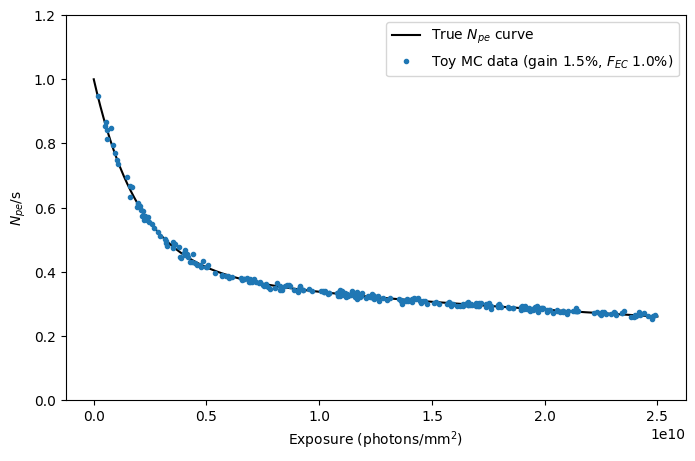

In [4]:
npe_clean = decay_npe(exposure, nominal_npe, amp_fast, tau_fast, amp_slow, tau_slow)
exp_toy, npe_toy = sample_toy_data(exposure, npe_clean, n_samples, gain_spread, fec_spread, seed=42)

plt.figure(figsize=(8,5))
# plotting relative changes to compare to Hiromu's initial plots from beamtime
plt.plot(exposure, npe_clean/npe_clean[0], "-", color="black", label = "True $N_{pe}$ curve")
plt.plot(exp_toy, npe_toy/npe_clean[0], ".", color = "tab:blue", label = f"Toy MC data (gain {gain_spread}%, $F_{{EC}}$ {fec_spread}%)")
plt.xlabel("Exposure (photons/mm$^2$)")
plt.ylabel(r"$N_{pe}$/s")
plt.ylim(0, 1.2)
plt.legend()
plt.show()

## Reconstruction from toy data only

In [7]:
# ORIGINAL METHOD FOR FITTING --> NOT THE BEST
# def fit_toy_data(exp_toy, npe_toy, p0=None, bounds=None):
#     """
#     from the toy MC data only, fit it to a double exponential
#     --> fit is bounded (upper and lower limits for each value) in order to isolate the two decay constants
#         --> this method performs poorly for estimating the slow amplitude/decay constants
#     """
#     if p0 is None:
#         p0 = [npe_toy[0], 8, 5e9, 2, 5e10]
#     if bounds is None:
#         lower = [0.5*npe_toy[0], 0, 1e8, 0, 1e10]
#         upper = [1.5*npe_toy[0], 10, 2e10, 5, 1e11]
#         bounds = (lower, upper)
#     popt, pcov = curve_fit(decay_npe, exp_toy, npe_toy, p0=p0, bounds=bounds, maxfev = 20000)
#     return popt, pcov

# NEW METHOD FOR FITTING --> ONLY FIT THE TIME CONSTANTS INSTEAD OF 5 PARAMETERS ==================
def solve_amplitudes(x, y, tau_fast, tau_slow):
    """
    once the fitter fits tau_fast, tau_slow use (non-negative) least squares regression to find best nominal/amp_fast/amp_slow
    --> if taus are fixed it is just a straight line (nominal) + 2 exponentials which an optimizer can solve for 
    """
    shapes = np.column_stack([np.ones_like(x), np.exp(-x/tau_fast), np.exp(-x/tau_slow)])
    amps, _ = nnls(shapes, y)
    residuals = (shapes @ amps)-y
    return amps, residuals

def residuals_vs_taus(log_taus, x, y):
    """
    function for optimizer to minimize --> residuals for best possible curve given two taus from fitter
    --> taus given as logs since looking at multiple orders of magnitude
    """
    tau_fast, tau_slow = np.exp(log_taus)
    amps, residuals = solve_amplitudes(x, y, tau_fast, tau_slow)
    return residuals/np.max(y) # --> divide by max to keep numbers around 1 for optimizer

def fit_toy_data(exp_toy, npe_toy, tau_fast_range=(1, 1e10), tau_slow_range=(1e10, 2e11)):
    """
    fit double exponential to toy MC data
    --> once taus are fit, this then gets sent to optimizer (multiple initial guesses for taus, keep whatever fits data best)
    """
    x = np.asarray(exp_toy)
    y = np.asarray(npe_toy)

    lower = np.log([tau_fast_range[0], tau_slow_range[0]])
    upper = np.log([tau_fast_range[1], tau_slow_range[1]])
    starting_guesses = [(3e9, 2e10), (5e9, 4e10), (8e9, 8e10), (2e9, 3e10), (4e9, 1e11)]

    best_fit = None
    for guess in starting_guesses:
        fit = least_squares(residuals_vs_taus, np.log(guess), bounds=(lower, upper), args=(x, y))
        if best_fit is None or fit.cost < best_fit.cost:
            best_fit = fit

    tau_fast, tau_slow = np.exp(best_fit.x)
    (baseline, a_fast, a_slow), _ = solve_amplitudes(x, y, tau_fast, tau_slow)
    nominal = baseline+a_fast+a_slow
    amp_fast = (a_fast/nominal)*100
    amp_slow = (a_slow/nominal)*100

    popt = np.array([nominal, amp_fast, tau_fast, amp_slow, tau_slow])
    return popt, np.full((5,5), np.nan)
# ===================================================================================================

def run_mc(exposure, npe_clean, n_samples, gain_spread, fec_spread, n_trials, p0=None, bounds=None, seed=42):
    """
    run the toy MC n_trials times, and fit the double exponential to it every time
    returns: nominal, amp+fast, tau_fast, amp_slow, tau_slow
    """
    rng = np.random.default_rng(seed)
    param_names = ["nominal", "amp_fast", "tau_fast", "amp_slow", "tau_slow"]
    results = {name: [] for name in param_names}
    n_failed = 0

    for i in range(n_trials):
        trial_seed = int(rng.integers(1e6))
        exp_toy, npe_toy = sample_toy_data(exposure, npe_clean, n_samples, gain_spread, fec_spread, seed=trial_seed)
        try:
            # popt, pcov = fit_toy_data(exp_toy, npe_toy, p0=p0, bounds=bounds) #for old fitter
            popt, pcov = fit_toy_data(exp_toy, npe_toy)
            for name, value in zip(param_names, popt):
                results[name].append(value)
        except (RuntimeError, ValueError):
            n_failed += 1
            continue

    print(f"{n_failed}/{n_trials} fits failed to converge")
    return {name: np.array(vals) for name, vals in results.items()}

def hist_panel(ax, vals, true, color, title, xlabel):
    """
    histogram with true-value line --> legend shows mean & frctional std as text
    """
    ax.hist(vals, bins=100, color = color)
    true_line = ax.axvline(true, linestyle = "--", color = "black")
    blank = Line2D([], [], linestyle="none", marker="none")
    handles = [true_line, blank, blank]
    labels = ["True Value", f"Mean = {np.mean(vals):.4g}", f"Std dev = {(np.std(vals)/np.mean(vals))*100:.4g}%"]
    ax.legend(handles, labels, loc=1, handlelength = 1.5, handletextpad = 0.5)
    ax.set_title(title) ; ax.set_xlabel(xlabel) ; ax.set_ylabel("Counts")

def summarize_mc(mc_results, true_values, n_trials, n_fit_plots):
    """
    summarizes results of run_mc making two plots:
    - 5 histograms of fitted parameters + 1 histogram of overall % decrease in N_pe
        --> also states mean of hist and fractional std  = (sigma/µ)*100
    - true decay lineshape overlaid with n_fit_plots sample fitted lineshapes
    """
    plot_idx = np.random.randint(0, len(mc_results["nominal"]), size=n_fit_plots)
    
    plt.figure(figsize=(8,5))
    for i in range(len(plot_idx)):
        if i == 0: 
            plt.plot(exposure, decay_npe(exposure, mc_results["nominal"][plot_idx[i]], mc_results["amp_fast"][plot_idx[i]], mc_results["tau_fast"][plot_idx[i]], 
                                mc_results["amp_slow"][plot_idx[i]], mc_results["tau_slow"][plot_idx[i]]), "-", color = "lightgrey", label = f"N = {n_fit_plots} fitted curves")
        else:
            plt.plot(exposure, decay_npe(exposure, mc_results["nominal"][plot_idx[i]], mc_results["amp_fast"][plot_idx[i]], mc_results["tau_fast"][plot_idx[i]], 
                                mc_results["amp_slow"][plot_idx[i]], mc_results["tau_slow"][plot_idx[i]]), "-", color = "lightgrey")
    
    plt.plot(exposure, decay_npe(exposure, true_values["nominal"], true_values["amp_fast"], true_values["tau_fast"], 
                                true_values["amp_slow"], true_values["tau_slow"]), "-", color = "black", label = "True $N_{pe}$ curve")
    plt.title("Comparison of True Curve with Fitted Examples") ; plt.xlabel("Exposure (photons/mm$^2$)") ; plt.ylabel(r"$N_{pe}$/s") ; plt.legend(loc=1)
    plt.show()

    fig, ax = plt.subplots(2, 3, figsize=(12,8))
    hist_panel(ax[0,0], mc_results["nominal"], true_values["nominal"], "darkorange", "Nominal", r"$N_{pe}$/s")
    hist_panel(ax[0,1], mc_results["amp_fast"], true_values["amp_fast"], "mediumturquoise", "Amp Fast", "% decreased")
    hist_panel(ax[0,2], mc_results["tau_fast"], true_values["tau_fast"], "teal", "Tau Fast", "Exposure (photons/mm$^2$)")
    hist_panel(ax[1,0], mc_results["amp_fast"]+mc_results["amp_slow"], true_values["amp_fast"]+true_values["amp_slow"], "darkviolet", "Total % Decrease (amp_fast+amp_slow)", "% decreased")
    hist_panel(ax[1,1], mc_results["amp_slow"], true_values["amp_slow"], "lightcoral", "Amp Slow", "% decreased")
    hist_panel(ax[1,2], mc_results["tau_slow"], true_values["tau_slow"], "firebrick", "Tau Slow", "Exposure (photons/mm$^2$)")

    fig.suptitle(f"Summary of n={n_trials} MC runs", fontsize=16)
    plt.tight_layout()
    plt.show()


In [8]:
n_trials = 10000

mc_results = run_mc(exposure, npe_clean, n_samples=n_samples, gain_spread=gain_spread, fec_spread=fec_spread, n_trials=n_trials, seed=1)
true_values = {"nominal": nominal_npe, "amp_fast": amp_fast, "tau_fast": tau_fast, "amp_slow": amp_slow, "tau_slow": tau_slow}

0/10000 fits failed to converge


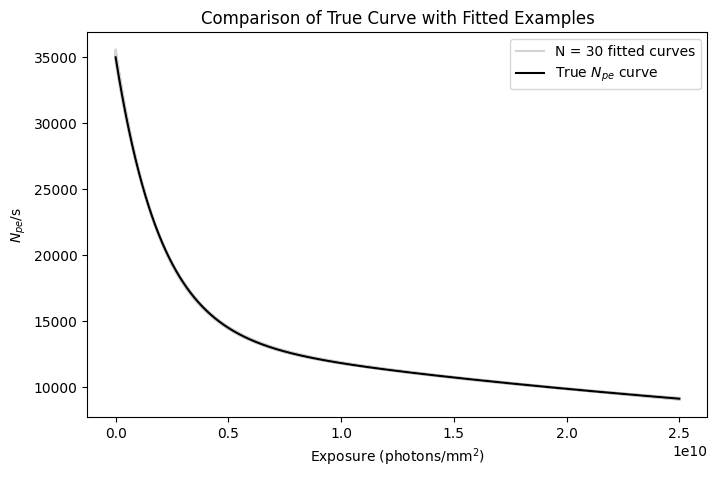

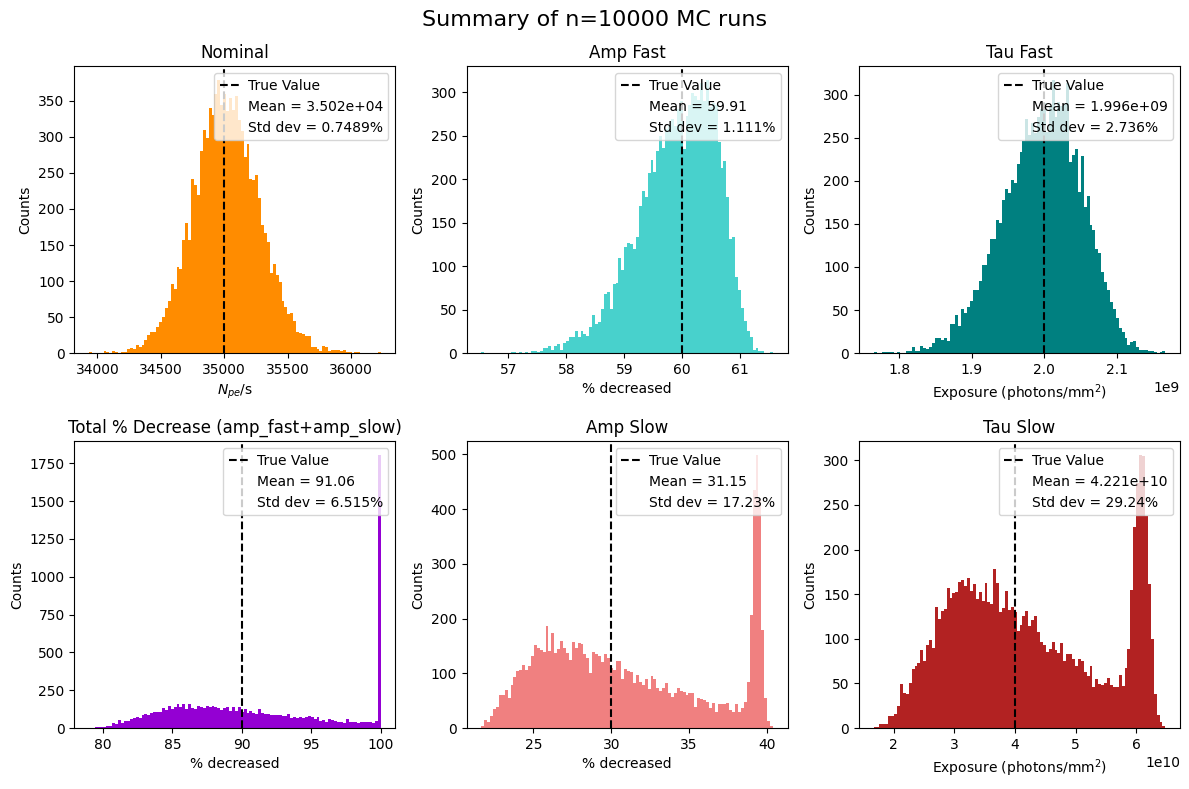

In [9]:
summarize_mc(mc_results, true_values, n_trials=n_trials, n_fit_plots=30)

## Precision vs number of datapoints

In [10]:
def data_vs_precision(exposure, npe_clean, n_samples, gain_spread, fec_spread, n_trials, seed=1):
    """
    run the toy MC with varying number of datapoints (n_samples)
    --> tells us how many alpha runs we need to take in order to recover a given precision in % decrease
    For each unique n_samples, run the MC n_trials times 
    """
    n_samples_results = {}
    for n in n_samples:
        n_samples_results[n] = run_mc(exposure, npe_clean, n, gain_spread, fec_spread, n_trials, seed=seed)
    return n_samples_results

def summarize_precision(mc_results, true_values, n_trials):
    """
    mc_results = {n_samples. run_mc output} from data_vs_precision
    plots the recovered mean +/- std dev vs n_samples for each parameter with true line as reference value
    """
    num_samp = np.array(sorted(mc_results.keys()))

    params = [("nominal", r"$N_{pe}$/s", "darkorange"), ("amp_fast", "Amp Fast", "mediumturquoise"), ("tau_fast", "Tau Fast", "teal"),
              ("total", "Total % Decrease (amp_fast+amp_slow)", "darkviolet"), ("amp_slow", "Amp Slow", "lightcoral"), ("tau_slow", "Tau Slow", "firebrick")]

    def get(result, name):
        return result["amp_fast"]+result["amp_slow"] if name == "total" else result[name]
    
    def true_val(name):
        return true_values["amp_fast"]+true_values["amp_slow"] if name == "total" else true_values[name]
    
    means = {name: np.array([np.mean(get(mc_results[n], name)) for n in num_samp]) for name, _, _ in params}
    stds = {name: np.array([np.std(get(mc_results[n], name)) for n in num_samp]) for name, _, _ in params}

    fig, ax = plt.subplots(2, 3, figsize = (12,8))
    for axs, (name, label, color) in zip(ax.flat, params):
        axs.errorbar(num_samp, means[name], yerr=stds[name], fmt="o", color=color, capsize=3, label="MC mean $\\pm$ std")
        axs.axhline(true_val(name), linestyle="--", color="black", label="True Value")
        axs.set_xscale("log")
        axs.set_title(label) ; axs.set_xlabel("n_samples (datapoints per fit)") ; axs.set_ylabel("Recovered value")
        axs.legend(loc=1, fontsize=8)

        for xi, yi, err in zip(num_samp, means[name], stds[name]):
            top_of_bar = yi+err
            axs.text(x=xi, y=top_of_bar+(0.1*err), s=f'{(err/yi)*100:.1f}%', ha='center', va='bottom', fontsize=8, color='black')
    
        axs.set_ylim(min(means[name]-stds[name])-0.2*min(means[name]-stds[name]), max(means[name]+stds[name])+0.2*max(means[name]+stds[name]))
        axs.set_xlim(min(num_samp)*0.8, max(num_samp)*1.2)
    fig.suptitle(f"Recovered parameters vs number of datapoints ({n_trials} trials each)")
    plt.tight_layout()
    plt.show()

0/1000 fits failed to converge
0/1000 fits failed to converge
0/1000 fits failed to converge
0/1000 fits failed to converge


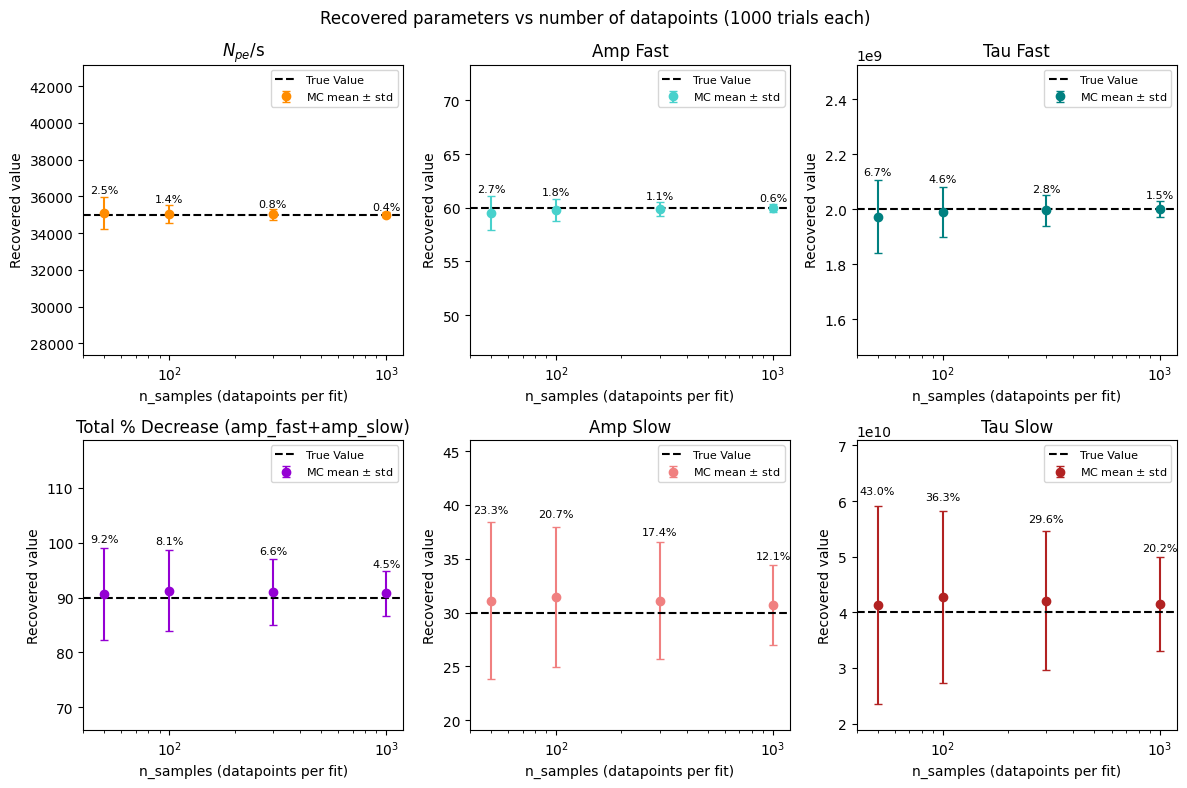

In [11]:
n_list = [50, 100, 300, 1000]
results = data_vs_precision(exposure, npe_clean, n_list, gain_spread, fec_spread, n_trials=1000)
summarize_precision(results, true_values, n_trials=1000)